<a href="https://colab.research.google.com/github/JorgeLuisMadrid/Aprendizaje-Maquina-2026B/blob/main/L06_Red_Neuronal_WeatherHistory.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Red Neuronal Densa: Predicción de Visibilidad Climática
Dataset: `weatherHistory.csv` — variable de interés: `Visibility (km)`.

## 1. Exploración del conjunto de datos y sus variables

Paso 1. Importamos la paquetería necesaria.

In [1]:
# Paquetería básica
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# TensorFlow y Keras
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import backend as K

# Utilidades de Sklearn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Paleta de colores consistente para todas las gráficas
COLOR_TRAIN = '#2a78d6'   # azul
COLOR_VAL   = '#eb6834'   # naranja
COLOR_AUX   = '#1baf7a'   # aqua

np.random.seed(42)
tf.random.set_seed(42)

/Users/jorgeluismadrid/Documents/AM/Aprendizaje-Maquina-2026B/.venv/lib/python3.9/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(


Paso 2. Descargamos y cargamos el dataset.

In [2]:
!rm -f "weatherHistory.csv"
!wget -q "https://raw.githubusercontent.com/JorgeLuisMadrid/Aprendizaje-Maquina-2026B/main/Datasets/weatherHistory.csv" -O "weatherHistory.csv"

dataset = pd.read_csv("weatherHistory.csv")
dataset.head()

,Formatted Date,Summary,Precip Type,Temperature (C),Apparent Temperature (C),Humidity,Wind Speed (km/h),Wind Bearing (degrees),Visibility (km),Loud Cover,Pressure (millibars),Daily Summary
0,2006-04-01 00:00:00.000 +0200,Partly Cloudy,rain,9.472222,7.388889,0.89,14.1197,251.0,15.8263,0.0,1015.13,Partly cloudy throughout the day.
1,2006-04-01 01:00:00.000 +0200,Partly Cloudy,rain,9.355556,7.227778,0.86,14.2646,259.0,15.8263,0.0,1015.63,Partly cloudy throughout the day.
2,2006-04-01 02:00:00.000 +0200,Mostly Cloudy,rain,9.377778,9.377778,0.89,3.9284,204.0,14.9569,0.0,1015.94,Partly cloudy throughout the day.
3,2006-04-01 03:00:00.000 +0200,Partly Cloudy,rain,8.288889,5.944444,0.83,14.1036,269.0,15.8263,0.0,1016.41,Partly cloudy throughout the day.
4,2006-04-01 04:00:00.000 +0200,Mostly Cloudy,rain,8.755556,6.977778,0.83,11.0446,259.0,15.8263,0.0,1016.51,Partly cloudy throughout the day.


Paso 3. Exploramos la estructura, los tipos de dato y las estadísticas descriptivas.

In [3]:
dataset.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 96453 entries, 0 to 96452
Data columns (total 12 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Formatted Date            96453 non-null  object 
 1   Summary                   96453 non-null  object 
 2   Precip Type               95936 non-null  object 
 3   Temperature (C)           96453 non-null  float64
 4   Apparent Temperature (C)  96453 non-null  float64
 5   Humidity                  96453 non-null  float64
 6   Wind Speed (km/h)         96453 non-null  float64
 7   Wind Bearing (degrees)    96453 non-null  float64
 8   Visibility (km)           96453 non-null  float64
 9   Loud Cover                96453 non-null  float64
 10  Pressure (millibars)      96453 non-null  float64
 11  Daily Summary             96453 non-null  object 
dtypes: float64(8), object(4)
memory usage: 8.8+ MB


In [4]:
dataset.describe()

,Temperature (C),Apparent Temperature (C),Humidity,Wind Speed (km/h),Wind Bearing (degrees),Visibility (km),Loud Cover,Pressure (millibars)
count,96453.000000,96453.000000,96453.000000,96453.000000,96453.000000,96453.000000,96453.0,96453.000000
mean,11.932678,10.855029,0.734899,10.810640,187.509232,10.347325,0.0,1003.235956
std,9.551546,10.696847,0.195473,6.913571,107.383428,4.192123,0.0,116.969906
min,-21.822222,-27.716667,0.000000,0.000000,0.000000,0.000000,0.0,0.000000
25%,4.688889,2.311111,0.600000,5.828200,116.000000,8.339800,0.0,1011.900000
50%,12.000000,12.000000,0.780000,9.965900,180.000000,10.046400,0.0,1016.450000
75%,18.838889,18.838889,0.890000,14.135800,290.000000,14.812000,0.0,1021.090000
max,39.905556,39.344444,1.000000,63.852600,359.000000,16.100000,0.0,1046.380000


Revisamos la cardinalidad de las variables categóricas y la distribución de la variable de interés.

Categorías en Summary       : 27
Categorías en Daily Summary : 214
Categorías en Precip Type   : ['rain' 'snow' nan]
Valores únicos de Loud Cover: [0.]


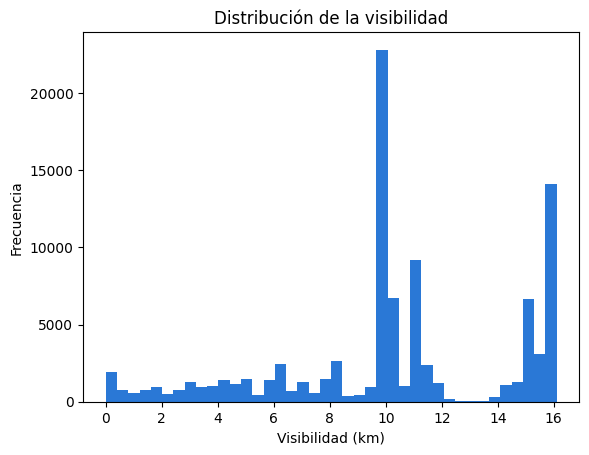

In [5]:
print('Categorías en Summary       :', dataset['Summary'].nunique())
print('Categorías en Daily Summary :', dataset['Daily Summary'].nunique())
print('Categorías en Precip Type   :', dataset['Precip Type'].unique())
print('Valores únicos de Loud Cover:', dataset['Loud Cover'].unique())

plt.figure()
plt.hist(dataset['Visibility (km)'], bins=40, color=COLOR_TRAIN)
plt.title('Distribución de la visibilidad')
plt.xlabel('Visibilidad (km)')
plt.ylabel('Frecuencia')
plt.show()

## 2. Limpieza del conjunto de datos y codificación de variables

Paso 4. Limpiamos y transformamos las columnas no numéricas:
- `Loud Cover` es constante (siempre 0), no aporta información y se elimina.
- `Daily Summary` es texto libre con 214 categorías distintas (prácticamente una por día); se elimina por su altísima cardinalidad.
- `Formatted Date` se convierte a fecha y de ella extraemos `Month` y `Hour` como variables numéricas; la columna original se elimina.
- `Precip Type` tiene valores faltantes, que interpretamos como ausencia de precipitación (`none`), y luego codificamos con one-hot.
- `Summary` se codifica con one-hot (27 categorías).

In [6]:
dataset = dataset.drop(columns=['Loud Cover', 'Daily Summary'])

fecha = pd.to_datetime(dataset['Formatted Date'], utc=True)
dataset['Month'] = fecha.dt.month
dataset['Hour'] = fecha.dt.hour
dataset = dataset.drop(columns=['Formatted Date'])

dataset['Precip Type'] = dataset['Precip Type'].fillna('none')

dataset = pd.get_dummies(dataset, columns=['Summary', 'Precip Type'])
dataset = dataset.astype({c: int for c in dataset.columns if dataset[c].dtype == bool})

print('Valores faltantes restantes:', dataset.isna().sum().sum())
print('Forma del dataset:', dataset.shape)
dataset.head()

Valores faltantes restantes: 0
Forma del dataset: (96453, 39)


,Temperature (C),Apparent Temperature (C),Humidity,Wind Speed (km/h),Wind Bearing (degrees),Visibility (km),Pressure (millibars),Month,Hour,Summary_Breezy,...,Summary_Rain,Summary_Windy,Summary_Windy and Dry,Summary_Windy and Foggy,Summary_Windy and Mostly Cloudy,Summary_Windy and Overcast,Summary_Windy and Partly Cloudy,Precip Type_none,Precip Type_rain,Precip Type_snow
0,9.472222,7.388889,0.89,14.1197,251.0,15.8263,1015.13,3,22,0,...,0,0,0,0,0,0,0,0,1,0
1,9.355556,7.227778,0.86,14.2646,259.0,15.8263,1015.63,3,23,0,...,0,0,0,0,0,0,0,0,1,0
2,9.377778,9.377778,0.89,3.9284,204.0,14.9569,1015.94,4,0,0,...,0,0,0,0,0,0,0,0,1,0
3,8.288889,5.944444,0.83,14.1036,269.0,15.8263,1016.41,4,1,0,...,0,0,0,0,0,0,0,0,1,0
4,8.755556,6.977778,0.83,11.0446,259.0,15.8263,1016.51,4,2,0,...,0,0,0,0,0,0,0,0,1,0


## 3. Variables de entrada y variable de salida

Paso 5. La variable de salida es `Visibility (km)`; el resto de las columnas son las variables de entrada.

In [7]:
x = np.asanyarray(dataset.drop(columns=['Visibility (km)']))
y = np.asanyarray(dataset[['Visibility (km)']])
print(x.shape)
print(y.shape)

(96453, 38)
(96453, 1)


## 4. Normalización y partición del conjunto de datos

Paso 6. Estandarizamos las variables de entrada y la variable de salida, y particionamos en entrenamiento (80%) y prueba (20%).

In [8]:
scaler_x = StandardScaler()
scaler_y = StandardScaler()

x = scaler_x.fit_transform(x)
y = scaler_y.fit_transform(y)

xtrain, xtest, ytrain, ytest = train_test_split(
    x, y, test_size=0.2, random_state=42)

print(xtrain.shape, xtest.shape)

(77162, 38) (19291, 38)


## 5. Diseño de la red neuronal

Paso 7. Al tratarse de un dataset mucho más grande (más de 96,000 registros), diseñamos una red densa más profunda, con tres capas ocultas, para el problema de regresión.

In [9]:
def r2score(y_true, y_pred):
    SS_res = K.sum(K.square(y_true - y_pred))
    SS_tot = K.sum(K.square(y_true - K.mean(y_true)))
    return 1 - SS_res / (SS_tot + K.epsilon())

def build_model(n_inputs, hidden1=128, hidden2=64, hidden3=32, dropout=0.2, lr=1e-3):
    model = keras.Sequential()
    model.add(keras.layers.Dense(hidden1, activation='relu', input_shape=[n_inputs]))
    model.add(keras.layers.Dropout(dropout))
    model.add(keras.layers.Dense(hidden2, activation='relu'))
    model.add(keras.layers.Dense(hidden3, activation='relu'))
    model.add(keras.layers.Dense(1, activation='linear'))

    model.compile(loss='mean_squared_error',
                  optimizer=keras.optimizers.Adam(learning_rate=lr),
                  metrics=[keras.metrics.MAE, r2score])
    return model

model = build_model(x.shape[1])
model.summary()

/Users/jorgeluismadrid/Documents/AM/Aprendizaje-Maquina-2026B/.venv/lib/python3.9/site-packages/keras/src/layers/core/dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │         4,992 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 15,361 (60.00 KB)

 Trainable params: 15,361 (60.00 KB)

 Non-trainable params: 0 (0.00 B)

## 6. Entrenamiento de la red y curvas de aprendizaje

Paso 8. Entrenamos la red con los hiperparámetros base. Usamos un `batch_size` más grande dado el tamaño del dataset.

In [10]:
history = model.fit(xtrain, ytrain,
                     batch_size=256, epochs=40,
                     validation_data=(xtest, ytest), verbose=0)
print('Última pérdida de validación:', history.history['val_loss'][-1])

Última pérdida de validación: 0.5282987952232361


Paso 9. Graficamos la evolución del entrenamiento a través de las épocas.

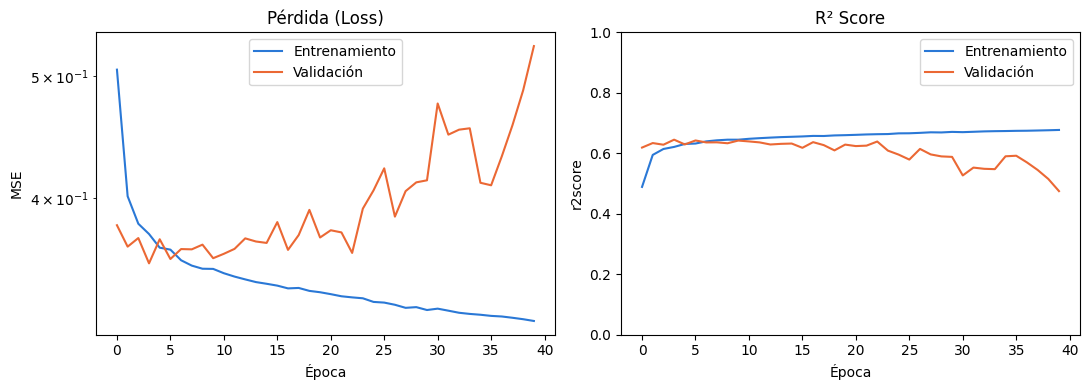

In [11]:
def plot_history(history):
    hist = pd.DataFrame(history.history)
    hist['epoch'] = history.epoch

    plt.figure(figsize=(11, 4))

    plt.subplot(1, 2, 1)
    plt.title('Pérdida (Loss)')
    plt.xlabel('Época')
    plt.ylabel('MSE')
    plt.plot(hist['epoch'], hist['loss'], color=COLOR_TRAIN, label='Entrenamiento')
    plt.plot(hist['epoch'], hist['val_loss'], color=COLOR_VAL, label='Validación')
    plt.yscale('log')
    plt.legend()

    plt.subplot(1, 2, 2)
    plt.title('R² Score')
    plt.xlabel('Época')
    plt.ylabel('r2score')
    plt.plot(hist['epoch'], hist['r2score'], color=COLOR_TRAIN, label='Entrenamiento')
    plt.plot(hist['epoch'], hist['val_r2score'], color=COLOR_VAL, label='Validación')
    plt.ylim([0, 1])
    plt.legend()

    plt.tight_layout()
    plt.show()

plot_history(history)

## 7. Búsqueda de hiperparámetros

Paso 10. Probamos distintas combinaciones de número de neuronas, `dropout` y tasa de aprendizaje, entrenando cada combinación con `EarlyStopping` y comparando el R² sobre el conjunto de validación.

In [12]:
configs = [
    dict(hidden1=64, hidden2=32, hidden3=16, dropout=0.1, lr=1e-3),
    dict(hidden1=128, hidden2=64, hidden3=32, dropout=0.2, lr=1e-3),
    dict(hidden1=128, hidden2=64, hidden3=32, dropout=0.3, lr=5e-4),
    dict(hidden1=256, hidden2=128, hidden3=64, dropout=0.2, lr=1e-3),
    dict(hidden1=256, hidden2=64, hidden3=32, dropout=0.3, lr=5e-4),
]

resultados = []
for cfg in configs:
    es = keras.callbacks.EarlyStopping(monitor='val_loss', mode='min', patience=5,
                                        restore_best_weights=True)
    m = build_model(x.shape[1], **cfg)
    h = m.fit(xtrain, ytrain, batch_size=256, epochs=40,
              validation_data=(xtest, ytest), verbose=0, callbacks=[es])
    val_loss = min(h.history['val_loss'])
    val_r2 = max(h.history['val_r2score'])
    resultados.append({**cfg, 'val_loss': val_loss, 'val_r2score': val_r2,
                        'epochs_entrenadas': len(h.epoch)})

resultados_df = pd.DataFrame(resultados).sort_values('val_r2score', ascending=False)
resultados_df

/Users/jorgeluismadrid/Documents/AM/Aprendizaje-Maquina-2026B/.venv/lib/python3.9/site-packages/keras/src/layers/core/dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


,hidden1,hidden2,hidden3,dropout,lr,val_loss,val_r2score,epochs_entrenadas
2,128,64,32,0.3,0.0005,0.330468,0.669811,40
4,256,64,32,0.3,0.0005,0.344056,0.656286,21
3,256,128,64,0.2,0.0010,0.345896,0.654426,12
1,128,64,32,0.2,0.0010,0.355068,0.645021,9
0,64,32,16,0.1,0.0010,0.367000,0.633396,13


Paso 11. Reentrenamos el modelo final con la mejor combinación de hiperparámetros encontrada.

Mejores hiperparámetros encontrados: {'hidden1': 128, 'hidden2': 64, 'hidden3': 32, 'dropout': np.float64(0.3), 'lr': np.float64(0.0005)}


/Users/jorgeluismadrid/Documents/AM/Aprendizaje-Maquina-2026B/.venv/lib/python3.9/site-packages/keras/src/layers/core/dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


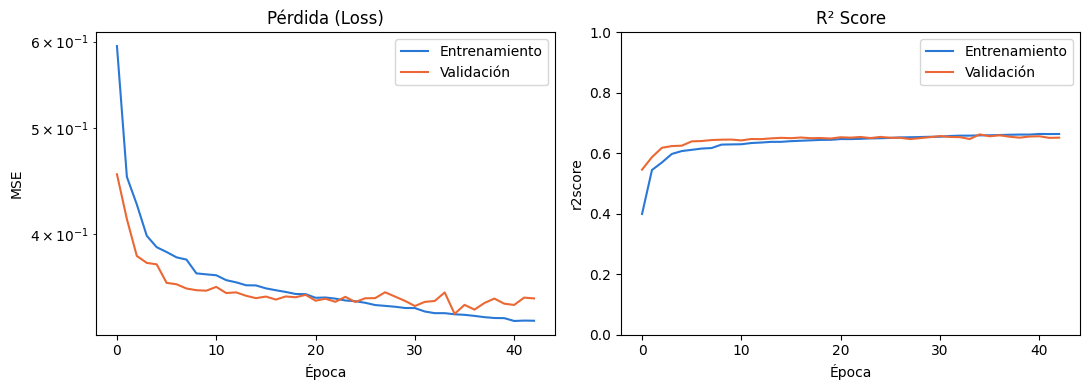

In [13]:
best_cfg = {k: resultados_df.iloc[0][k] for k in ['hidden1', 'hidden2', 'hidden3', 'dropout', 'lr']}
for k in ['hidden1', 'hidden2', 'hidden3']:
    best_cfg[k] = int(best_cfg[k])
print('Mejores hiperparámetros encontrados:', best_cfg)

es = keras.callbacks.EarlyStopping(monitor='val_loss', mode='min', patience=8,
                                    restore_best_weights=True)
final_model = build_model(x.shape[1], **best_cfg)
history_final = final_model.fit(xtrain, ytrain, batch_size=256, epochs=80,
                                 validation_data=(xtest, ytest), verbose=0,
                                 callbacks=[es])
plot_history(history_final)

## 8. Métricas de desempeño

Paso 12. Calculamos las métricas de regresión sobre el conjunto de prueba, revirtiendo la normalización para expresarlas en la escala original (km).

In [14]:
y_pred_scaled = final_model.predict(xtest, verbose=0)
y_pred = scaler_y.inverse_transform(y_pred_scaled)
y_real = scaler_y.inverse_transform(ytest)

mae = mean_absolute_error(y_real, y_pred)
rmse = np.sqrt(mean_squared_error(y_real, y_pred))
r2 = r2_score(y_real, y_pred)

print(f'MAE  : {mae:.3f} km')
print(f'RMSE : {rmse:.3f} km')
print(f'R2   : {r2:.4f}')

MAE  : 1.840 km
RMSE : 2.436 km
R2   : 0.6644


Paso 13. Visualizamos la visibilidad predicha contra la visibilidad real.

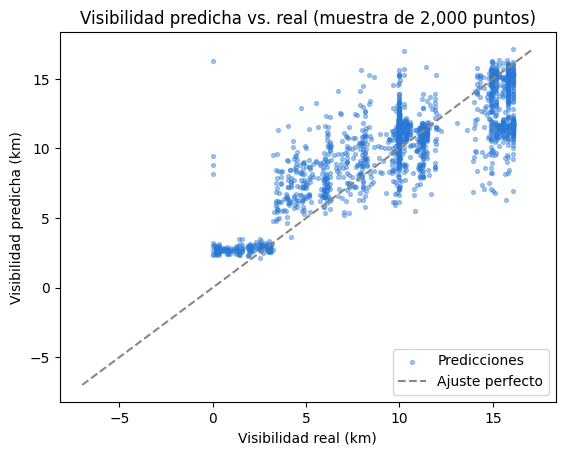

In [15]:
muestra = np.random.choice(len(y_real), size=2000, replace=False)

plt.figure()
plt.scatter(y_real[muestra], y_pred[muestra], color=COLOR_TRAIN, s=8, alpha=0.4,
            label='Predicciones')
lims = [min(y_real.min(), y_pred.min()), max(y_real.max(), y_pred.max())]
plt.plot(lims, lims, '--', color='#898781', label='Ajuste perfecto')
plt.title('Visibilidad predicha vs. real (muestra de 2,000 puntos)')
plt.xlabel('Visibilidad real (km)')
plt.ylabel('Visibilidad predicha (km)')
plt.legend()
plt.show()